# ClimSim tutorial

This notebook does all steps of the repository with a small quantity of data.

1. Download a small part of the data.
2. Open a store with xarray.
3. Look at the data.
4. Find the model and the training code.
5. Train a small model and score it.
6. Plot the scores as in Figure 2 of the ClimSim paper (Yu et al. 2023).

Run the cells from the top to the bottom.
`GLOSSARY.md` explains the terms of atmospheric physics and the names of the variables.

## 1. Download

`fetch_data.run` downloads the raw files from Hugging Face and writes two stores.
For this tutorial, the strides are larger than the defaults of `fetch_data.py`:

| Store | Months | Stride | Timesteps |
| --- | --- | --- | --- |
| `data/tutorial/train.zarr` | 0001-02 to 0007-12 | every 713th timestep | 255 |
| `data/tutorial/test.zarr` | 0008-02 to 0009-01 | every 60th timestep | 438 |

The download is approximately 2 GB and takes some minutes.
If the stores are complete, the cell does nothing.

In [14]:
from pathlib import Path
DATA = Path("data/tutorial")

## 2. The store

A store is a zarr directory that xarray opens as a `Dataset`.
Each variable has the dimensions `(time, ncol, level)` or `(time, ncol)`.

- `time`: one value for each timestep of the simulation. The calendar has no leap years.
- `ncol`: the 384 columns of the grid. `lat`, `lon`, and `area` give the position and the area of each column.
- `level`: the 60 levels of the atmosphere. Level 0 is the top and level 59 is adjacent to the surface.

`hyai`, `hybi`, and `P0` are constants of the levels. `score.py` uses them.

In [15]:
import xarray as xr

train = xr.open_zarr(DATA / "train.zarr")
test = xr.open_zarr(DATA / "test.zarr")

LABELS = {  # name in the store: (term of the glossary, unit)
    "state_t": ("Air temperature", "K"),
    "ptend_t": ("Heating tendency", "K/s"),
    "ptend_q0001": ("Moistening tendency", "kg/kg/s"),
    "cam_out_NETSW": ("Net shortwave flux", "W/m2"),
    "cam_out_FLWDS": ("Downward longwave flux", "W/m2"),
    "cam_out_PRECSC": ("Snow rate", "m/s"),
    "cam_out_PRECC": ("Rain rate", "m/s"),
    "cam_out_SOLS": ("Visible direct solar flux", "W/m2"),
    "cam_out_SOLL": ("Near-infrared direct solar flux", "W/m2"),
    "cam_out_SOLSD": ("Visible diffuse solar flux", "W/m2"),
    "cam_out_SOLLD": ("Near-infrared diffuse solar flux", "W/m2"),
}
for name, (term, unit) in LABELS.items():
    train[name].attrs = {"long_name": term, "units": unit}
train["level"].attrs = {"long_name": "Level (0 is the top)"}
train

<xarray.Dataset> Size: 99MB
Dimensions:         (time: 255, ncol: 384, ilev: 61, level: 60)
Coordinates:
  * time            (time) object 2kB 0001-02-01 00:00:00 ... 0007-12-23 07:2...
  * ncol            (ncol) int64 3kB 0 1 2 3 4 5 6 ... 378 379 380 381 382 383
    area            (ncol) float64 3kB dask.array<chunksize=(384,), meta=np.ndarray>
    lat             (ncol) float32 2kB dask.array<chunksize=(384,), meta=np.ndarray>
    lon             (ncol) float32 2kB dask.array<chunksize=(384,), meta=np.ndarray>
  * ilev            (ilev) float64 488B 0.05588 0.1008 0.1814 ... 985.3 1e+03
  * level           (level) int64 480B 0 1 2 3 4 5 6 7 ... 53 54 55 56 57 58 59
Data variables: (12/19)
    cam_out_FLWDS   (time, ncol) float32 392kB dask.array<chunksize=(32, 384), meta=np.ndarray>
    cam_out_NETSW   (time, ncol) float32 392kB dask.array<chunksize=(32, 384), meta=np.ndarray>
    cam_out_PRECC   (time, ncol) float32 392kB dask.array<chunksize=(32, 384), meta=np.ndarray>
    cam_out_PRECSC  (time, ncol) float32 392kB dask.array<chunksize=(32, 384), meta=np.ndarray>
    cam_out_SOLL    (time, ncol) float32 392kB dask.array<chunksize=(32, 384), meta=np.ndarray>
    cam_out_SOLLD   (time, ncol) float32 392kB dask.array<chunksize=(32, 384), meta=np.ndarray>
    ...              ...
    pbuf_SOLIN      (time, ncol) float32 392kB dask.array<chunksize=(32, 384), meta=np.ndarray>
    ptend_q0001     (time, ncol, level) float32 24MB dask.array<chunksize=(32, 384, 60), meta=np.ndarray>
    ptend_t         (time, ncol, level) float32 24MB dask.array<chunksize=(32, 384, 60), meta=np.ndarray>
    state_ps        (time, ncol) float32 392kB dask.array<chunksize=(32, 384), meta=np.ndarray>
    state_q0001     (time, ncol, level) float32 24MB dask.array<chunksize=(32, 384, 60), meta=np.ndarray>
    state_t         (time, ncol, level) float32 24MB dask.array<chunksize=(32, 384, 60), meta=np.ndarray>
Attributes:
    source:      LEAP/ClimSim_low-res on Hugging Face, E3SM-MMF low resolutio...
    timesteps:   0001-02-01 00:00:00 to 0007-12-23 07:20:00, 255 timesteps
    tendencies:  ptend = (mlo.state - mli.state) / 1200 s

In [16]:
train.sel(time=slice("0003-01", "0003-12"))["state_t"]   # select months with the calendar

<xarray.DataArray 'state_t' (time: 37, ncol: 384, level: 60)> Size: 3MB
dask.array<getitem, shape=(37, 384, 60), dtype=float32, chunksize=(25, 384, 60), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) object 296B 0003-01-05 02:20:00 ... 0003-12-27 14:20:00
  * ncol     (ncol) int64 3kB 0 1 2 3 4 5 6 7 ... 377 378 379 380 381 382 383
    area     (ncol) float64 3kB dask.array<chunksize=(384,), meta=np.ndarray>
    lat      (ncol) float32 2kB dask.array<chunksize=(384,), meta=np.ndarray>
    lon      (ncol) float32 2kB dask.array<chunksize=(384,), meta=np.ndarray>
  * level    (level) int64 480B 0 1 2 3 4 5 6 7 8 ... 51 52 53 54 55 56 57 58 59
Attributes:
    long_name:  Air temperature
    units:      K

## 3. A look at the data

### A vertical profile

The heating tendency `ptend_t` is a target: the rate of change of the temperature at each level.
The plot shows three columns at one time.
The values near the top (level 0) are small in comparison with the values in the lower atmosphere.

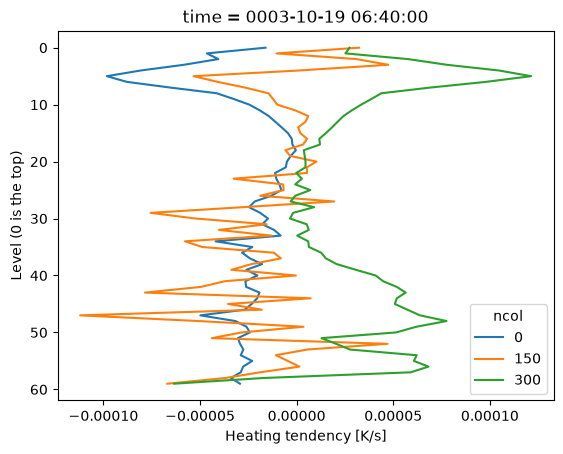

In [17]:
train["ptend_t"].isel(time=100, ncol=[0, 150, 300]).plot.line(y="level", hue="ncol", yincrease=False);

### The distribution of one variable

The rain rate `cam_out_PRECC` is zero in most rows and large in a small number of rows.
The vertical axis is logarithmic.

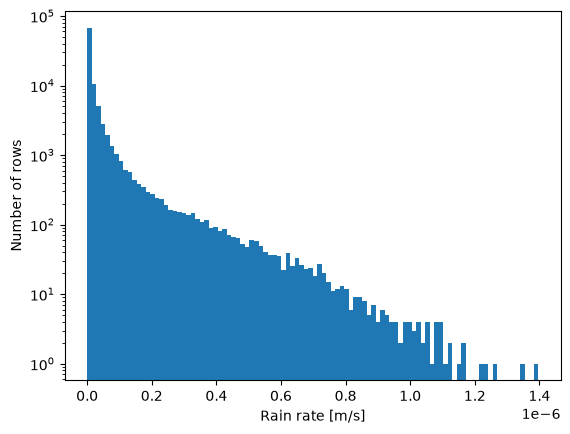

In [18]:
import matplotlib.pyplot as plt

train["cam_out_PRECC"].plot.hist(bins=100, yscale="log")
plt.ylabel("Number of rows");

### A time series

The mean temperature of all columns at the level adjacent to the surface, with the area of each column as weight.
The stride of 713 timesteps gives one value for each 9.9 days. The plot shows the cycle of the year.

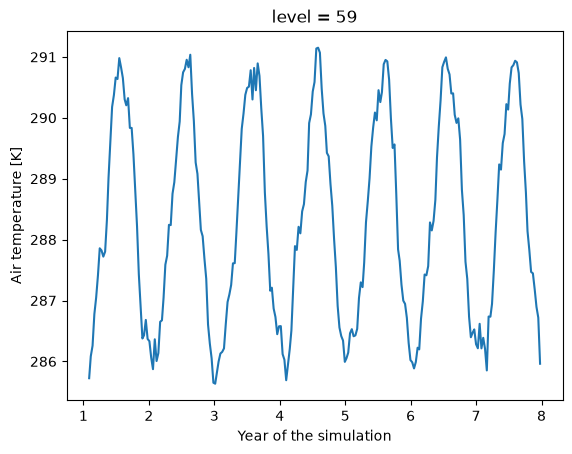

In [19]:
series = train["state_t"].isel(level=-1).weighted(train["area"]).mean("ncol", keep_attrs=True)
series = series.assign_coords(year=train["time"].dt.year + train["time"].dt.dayofyear / 365)
series.plot(x="year")
plt.xlabel("Year of the simulation");

## 4. The model and the training code

| File | Contents | What you can change there |
| --- | --- | --- |
| `utils/paper_mlp.py` | `MLP`, the example model | The architecture of the network |
| `utils/dataset.py` | `ClimSimData` | The variables that the model gets, and the standardisation |
| `utils/lightning_module.py` | `ClimSimModule` | The loss (`training_step`), the optimiser and the learning rate (`configure_optimizers`, `lr_factor`), the validation data, and the test step |
| `configs/*.yaml` | One configuration for each run | The sizes of the layers, the batch size, the number of steps, the learning rate |
| `score.py` | The metrics | Add a metric as one function |

The model gets the standardised inputs of one row, 124 values, and predicts the standardised targets, 128 values.
`ClimSimData.to_xarray` changes predictions back to physical units on `(time, ncol, level)`.

In [20]:
import inspect

from utils.paper_mlp import MLP

print(inspect.getsource(MLP))

class MLP(nn.Module):
    """The MLP of the ClimSim paper (Yu et al. 2023, SI section 3).

    `floor` is the smallest value of each output.  The paper applies a ReLU to the eight surface outputs, because
    these fluxes and rates are not negative.  With standardised targets, zero in physical units is not zero for the
    network.  Thus the floor of a surface output is the standardised value of zero.  The other outputs have no floor.
    """

    def __init__(self, n_in: int, n_out: int, hidden: tuple = (768, 640, 512, 640, 640, 128), negative_slope: float = 0.15,
                 floor: torch.Tensor | None = None):
        super().__init__()
        widths = [n_in, *hidden]
        self.body = nn.Sequential(*[m for a, b in zip(widths[:-1], widths[1:])
                                    for m in (nn.Linear(a, b), nn.LeakyReLU(negative_slope))])
        self.head = nn.Linear(widths[-1], n_out)
        self.register_buffer("floor", floor if floor is not None else torch.full((n_out,), -

In [21]:
from utils.dataset import ClimSimData

data = ClimSimData(DATA / "train.zarr")
data.x.shape, data.y.shape   # (rows, input values), (rows, target values)

(torch.Size([97920, 124]), torch.Size([97920, 128]))

## 5. Train a small model and score it

`configs/tutorial.yaml` trains an MLP with three hidden layers for 2000 steps.
`run` trains the model, then the test step predicts the test data and calculates the scores.
The outputs are in `runs/tutorial/seed0/`.

In [22]:
run_dir = Path("runs/tutorial/seed0")

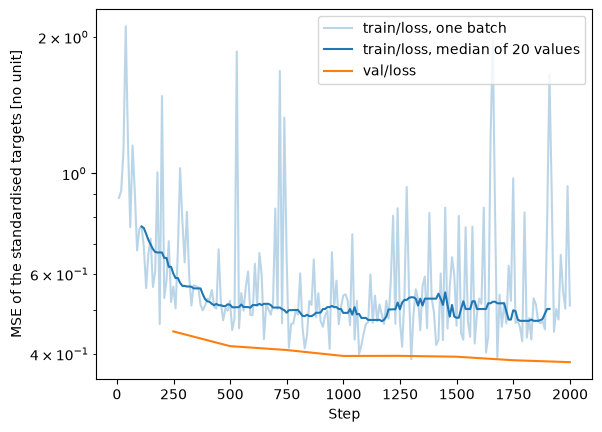

In [23]:
import pandas as pd

metrics = pd.read_csv(run_dir / "metrics.csv")
loss = metrics.dropna(subset="train/loss").set_index("step")["train/loss"]
ax = loss.plot(alpha=0.3, label="train/loss, one batch")
loss.rolling(20, center=True).median().plot(ax=ax, color="C0", label="train/loss, median of 20 values")
metrics.dropna(subset="val/loss").plot(x="step", y="val/loss", ax=ax, color="C1")
ax.set(xlabel="Step", ylabel="MSE of the standardised targets [no unit]", yscale="log")
ax.legend();

The loss of one batch has large peaks. They do not come from the optimiser.
A small number of rows have very large values of the moistening tendency in the upper levels, and a batch that contains such a row has a large loss.
The dark line is the median of 20 values. It shows the trend.

The test step wrote `predictions.zarr`, because the configuration has `store_predictions: true`.
`score.py` calculates the scores from this store. The scores are the same as the scores of the test step.

In [24]:
%run score.py {run_dir}/predictions.zarr --truth {DATA}/test.zarr

metric          r2_kaggle      r2   mae       mse
variable                                         
ptend_t            0.5323   0.491 3.153     58.22
ptend_q0001        0.4093 -0.5398 5.061     207.3
cam_out_NETSW      0.9573  0.9115 26.59      2576
cam_out_FLWDS      0.9694  0.7722 9.649     162.2
cam_out_PRECSC     0.6034  -82.79 4.063     134.8
cam_out_PRECC      0.6564  -510.4 49.07 1.454e+04
cam_out_SOLS       0.9278  0.8836 13.99     871.6
cam_out_SOLL       0.9127  0.8683 16.72      1174
cam_out_SOLSD      0.8945  0.8905 7.549     227.6
cam_out_SOLLD      0.7609  0.7368 7.199     209.8
Kaggle score: 0.4935


## 6. The scores as in Figure 2 of the ClimSim paper

`scores.zarr` has one variable for each target, with the dimensions `(metric, level)`.

Figure 2 of the paper shows the MAE of each target, and the MAE and the R2 of the heating tendency and the
moistening tendency at each level. The plots below show the same quantities for the model of this tutorial.
The values are not the values of the paper: this model is small, and the training data is 1/31 of the full data.

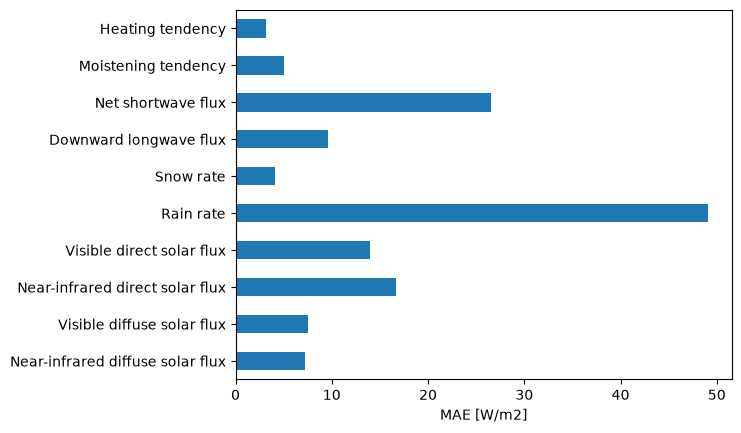

In [25]:
from utils.dataset import TARGETS

scores = xr.open_zarr(run_dir / "scores.zarr")[TARGETS]
mae = scores.sel(metric="mae").mean("level").to_array("variable").to_pandas()
mae.rename(lambda name: LABELS[name][0]).plot.barh(xlabel="MAE [W/m2]", ylabel="").invert_yaxis();

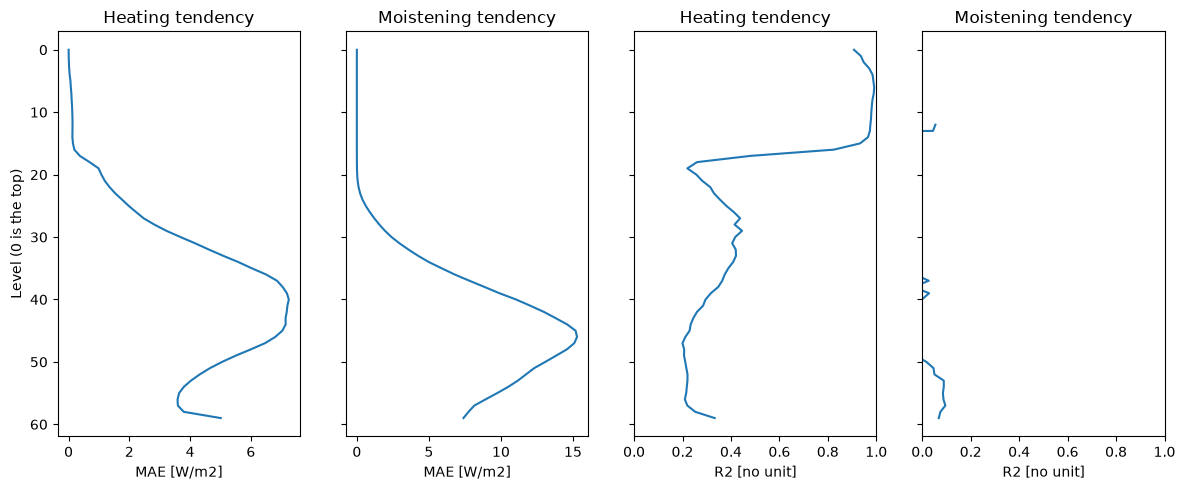

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(12, 5), sharey=True)
panels = [(name, metric) for metric in ["mae", "r2"] for name in ["ptend_t", "ptend_q0001"]]
for ax, (name, metric) in zip(axes, panels):
    scores[name].sel(metric=metric).plot(ax=ax, y="level", yincrease=False)
    ax.set(title=LABELS[name][0], xlabel="MAE [W/m2]" if metric == "mae" else "R2 [no unit]", ylabel="")
axes[0].set_ylabel("Level (0 is the top)")
axes[2].set_xlim(0, 1)
axes[3].set_xlim(0, 1)
fig.tight_layout()

Where the R2 is less than 0, the line is to the left of the plot, as in the figure of the paper.
The R2 has no value at the levels where the target is constant in all columns.

To continue, run the full download and the configuration of the paper:

```
python fetch_data.py
python experiment.py --config configs/paper_mlp.yaml
```